In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:

import zipfile
import urllib.request
import os

url = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"

urllib.request.urlretrieve(url, "electricity_data.zip")

with zipfile.ZipFile("electricity_data.zip", "r") as zip_ref:
    zip_ref.extractall("electricity_data")

print("Dataset downloaded and extracted successfully!")


Dataset downloaded and extracted successfully!


In [ ]:

import pandas as pd

file_path = "electricity_data/household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [ ]:

print("Dataset Information:")
print("--------------------")

print("Number of rows and columns:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Data Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())


Dataset Information:
--------------------
Number of rows and columns: (2075259, 9)

Column Names:
['Date', 'Time', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3']

Dataset Data Types:
Date                      object
Time                      object
Global_active_power      float64
Global_reactive_power    float64
Voltage                  float64
Global_intensity         float64
Sub_metering_1           float64
Sub_metering_2           float64
Sub_metering_3           float64
dtype: object

Missing Values:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64


In [ ]:

print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Missing Values in Each Column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

Total Missing Values:
181853


In [ ]:

# Create a cleaned copy of the dataset
df_clean = df.dropna().copy()

# Check the results
print("Original dataset rows:", len(df))
print("Rows after cleaning:", len(df_clean))
print("Rows removed:", len(df) - len(df_clean))
print("Missing values remaining:", df_clean.isnull().sum().sum())


Original dataset rows: 2075259
Rows after cleaning: 2049280
Rows removed: 25979
Missing values remaining: 0


In [ ]:

# Convert Date and Time into a single datetime column
df_clean["Datetime"] = pd.to_datetime(
    df_clean["Date"] + " " + df_clean["Time"],
    dayfirst=True
)

# Extract useful time information
df_clean["Year"] = df_clean["Datetime"].dt.year
df_clean["Month"] = df_clean["Datetime"].dt.month
df_clean["Hour"] = df_clean["Datetime"].dt.hour
df_clean["Day"] = df_clean["Datetime"].dt.date

print("Date and time conversion completed!")
print(df_clean[["Datetime", "Year", "Month", "Day", "Hour"]].head())


Date and time conversion completed!
             Datetime  Year  Month         Day  Hour
0 2006-12-16 17:24:00  2006     12  2006-12-16    17
1 2006-12-16 17:25:00  2006     12  2006-12-16    17
2 2006-12-16 17:26:00  2006     12  2006-12-16    17
3 2006-12-16 17:27:00  2006     12  2006-12-16    17
4 2006-12-16 17:28:00  2006     12  2006-12-16    17


In [ ]:

# Calculate daily electricity consumption
df_clean["Energy_kWh"] = df_clean["Global_active_power"] / 60

daily_consumption = (
    df_clean.groupby("Day")["Energy_kWh"]
    .sum()
    .reset_index()
)

daily_consumption.columns = ["Date", "Daily_Consumption_kWh"]

print("Daily consumption calculated successfully!")
print(daily_consumption.head())
print("\nTotal days analyzed:", len(daily_consumption))


Daily consumption calculated successfully!
         Date  Daily_Consumption_kWh
0  2006-12-16              20.152933
1  2006-12-17              56.507667
2  2006-12-18              36.730433
3  2006-12-19              27.769900
4  2006-12-20              37.095800

Total days analyzed: 1433


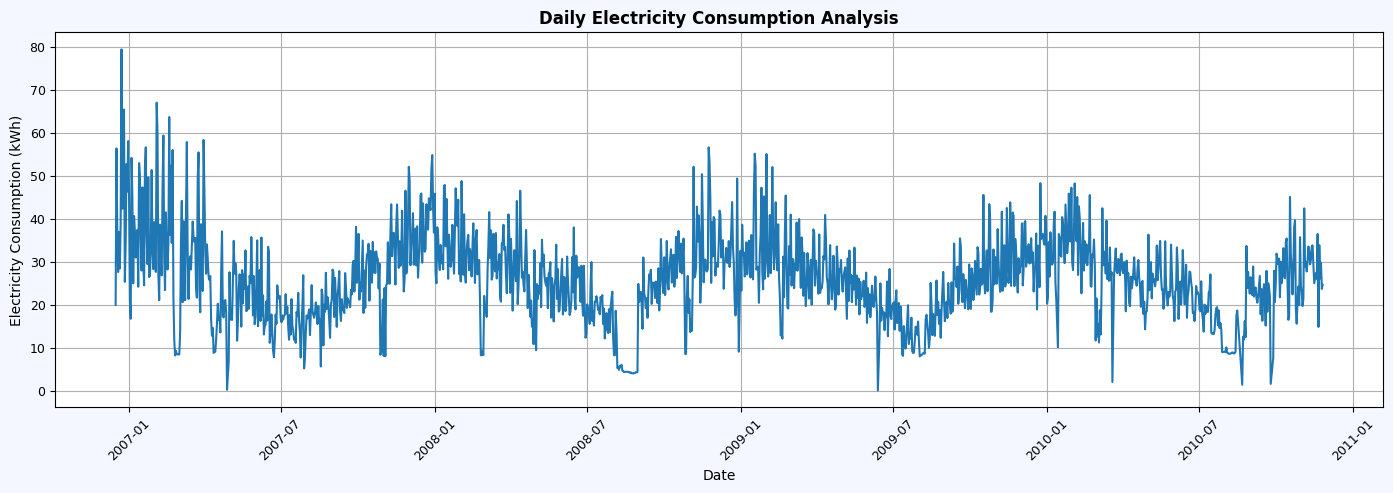

In [ ]:

plt.figure(figsize=(14, 5))

plt.plot(
    daily_consumption["Date"],
    daily_consumption["Daily_Consumption_kWh"]
)

plt.title("Daily Electricity Consumption Analysis")
plt.xlabel("Date")
plt.ylabel("Electricity Consumption (kWh)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


In [ ]:

# Calculate monthly electricity consumption
df_clean["YearMonth"] = df_clean["Datetime"].dt.to_period("M")

monthly_consumption = (
    df_clean.groupby("YearMonth")["Energy_kWh"]
    .sum()
    .reset_index()
)

monthly_consumption["YearMonth"] = (
    monthly_consumption["YearMonth"].astype(str)
)

monthly_consumption.columns = [
    "Month", "Monthly_Consumption_kWh"
]

print("Monthly consumption calculated successfully!")
print(monthly_consumption.head())


Monthly consumption calculated successfully!
     Month  Monthly_Consumption_kWh
0  2006-12               696.888033
1  2007-01              1150.197700
2  2007-02               941.481433
3  2007-03               981.036533
4  2007-04               586.357767


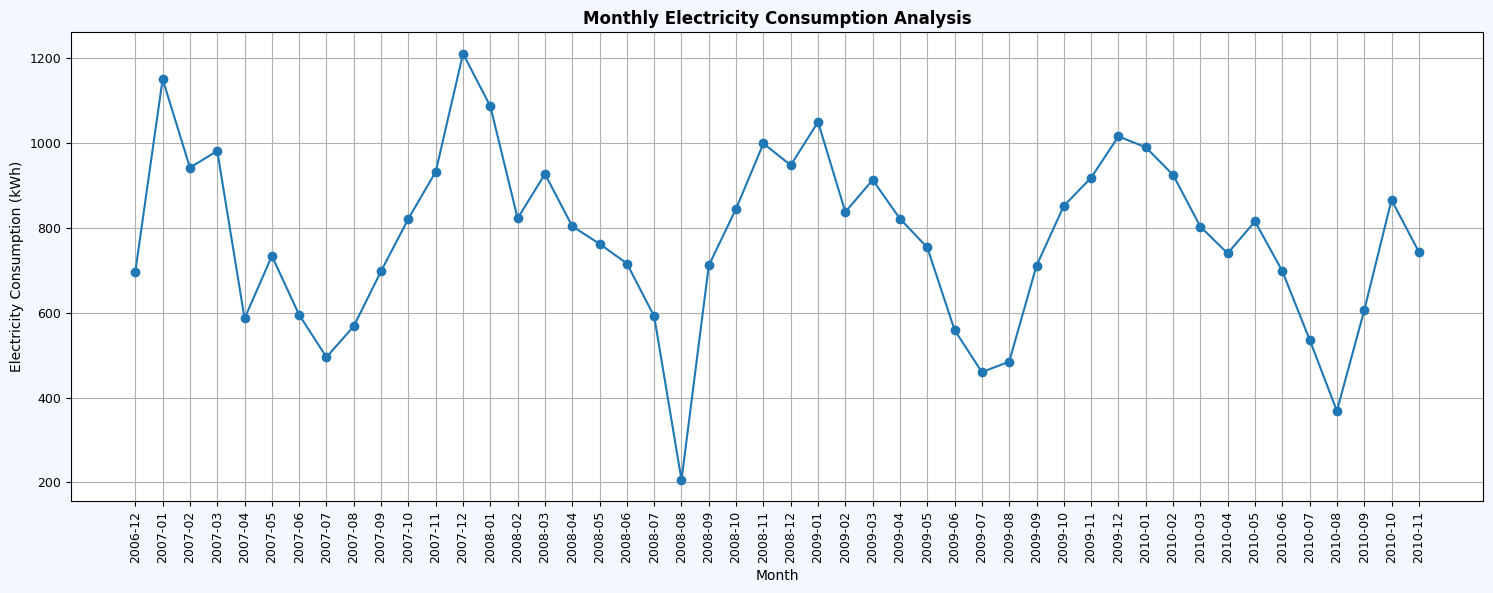

In [ ]:

plt.figure(figsize=(15, 6))

plt.plot(
    monthly_consumption["Month"],
    monthly_consumption["Monthly_Consumption_kWh"],
    marker="o"
)

plt.title("Monthly Electricity Consumption Analysis")
plt.xlabel("Month")
plt.ylabel("Electricity Consumption (kWh)")
plt.xticks(rotation=90)
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:

# Find the month with highest consumption
highest_month = monthly_consumption.loc[
    monthly_consumption["Monthly_Consumption_kWh"].idxmax()
]

# Find the month with lowest consumption
lowest_month = monthly_consumption.loc[
    monthly_consumption["Monthly_Consumption_kWh"].idxmin()
]

print("HIGHEST CONSUMPTION MONTH")
print("Month:", highest_month["Month"])
print("Consumption:", round(highest_month["Monthly_Consumption_kWh"], 2), "kWh")

print("\nLOWEST CONSUMPTION MONTH")
print("Month:", lowest_month["Month"])
print("Consumption:", round(lowest_month["Monthly_Consumption_kWh"], 2), "kWh")


HIGHEST CONSUMPTION MONTH
Month: 2007-12
Consumption: 1210.07 kWh

LOWEST CONSUMPTION MONTH
Month: 2008-08
Consumption: 205.7 kWh


In [ ]:

print("ELECTRICITY CONSUMPTION SUMMARY")
print("--------------------------------")

print("Average daily consumption:",
      round(daily_consumption["Daily_Consumption_kWh"].mean(), 2), "kWh")

print("Highest daily consumption:",
      round(daily_consumption["Daily_Consumption_kWh"].max(), 2), "kWh")

print("Lowest daily consumption:",
      round(daily_consumption["Daily_Consumption_kWh"].min(), 2), "kWh")

print("Total consumption across analyzed days:",
      round(daily_consumption["Daily_Consumption_kWh"].sum(), 2), "kWh")

print("Number of days analyzed:",
      len(daily_consumption))


ELECTRICITY CONSUMPTION SUMMARY
--------------------------------
Average daily consumption: 26.02 kWh
Highest daily consumption: 79.56 kWh
Lowest daily consumption: 0.24 kWh
Total consumption across analyzed days: 37283.75 kWh
Number of days analyzed: 1433


In [ ]:

# Calculate average electricity consumption by hour
hourly_consumption = (
    df_clean.groupby("Hour")["Global_active_power"]
    .mean()
    .reset_index()
)

hourly_consumption.columns = [
    "Hour", "Average_Power_kW"
]

print("Average electricity usage by hour:")
print(hourly_consumption)

# Find the hour with the highest average power
peak_hour = hourly_consumption.loc[
    hourly_consumption["Average_Power_kW"].idxmax()
]

print("\nPeak usage hour:", int(peak_hour["Hour"]))
print("Average power:", round(peak_hour["Average_Power_kW"], 2), "kW")


Average electricity usage by hour:
    Hour  Average_Power_kW
0      0          0.659434
1      1          0.539325
2      2          0.480621
3      3          0.444866
4      4          0.443847
5      5          0.453674
6      6          0.791600
7      7          1.502246
8      8          1.461016
9      9          1.331645
10    10          1.260627
11    11          1.245822
12    12          1.207075
13    13          1.144532
14    14          1.082839
15    15          0.990760
16    16          0.948905
17    17          1.055109
18    18          1.326451
19    19          1.733335
20    20          1.899064
21    21          1.877697
22    22          1.412615
23    23          0.902142

Peak usage hour: 20
Average power: 1.9 kW


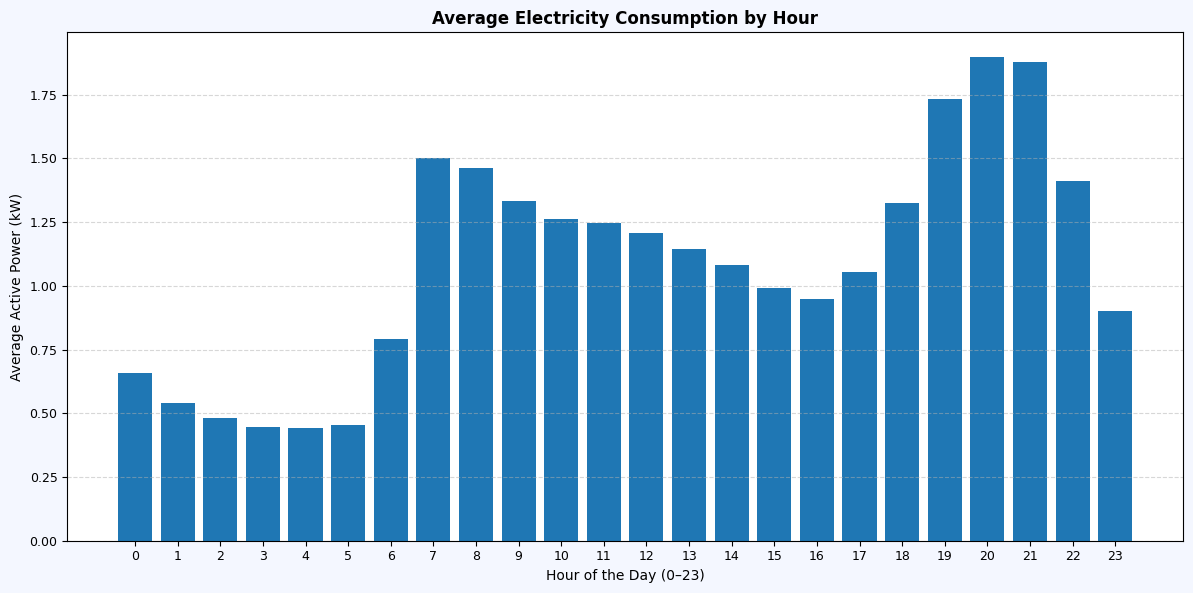

In [ ]:

plt.figure(figsize=(12, 6))

plt.bar(
    hourly_consumption["Hour"],
    hourly_consumption["Average_Power_kW"]
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of the Day (0–23)")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()


In [ ]:

# Find the 10 days with the highest electricity consumption
top_10_days = daily_consumption.sort_values(
    by="Daily_Consumption_kWh",
    ascending=False
).head(10)

print("TOP 10 HIGHEST ELECTRICITY CONSUMPTION DAYS")
print(top_10_days.to_string(index=False))


TOP 10 HIGHEST ELECTRICITY CONSUMPTION DAYS
      Date  Daily_Consumption_kWh
2006-12-23              79.556433
2007-02-03              67.162033
2006-12-26              65.568500
2007-02-18              63.829367
2007-02-04              59.932333
2007-02-11              59.520467
2007-03-31              58.491833
2006-12-31              58.236600
2007-03-11              58.010600
2007-01-21              56.787700


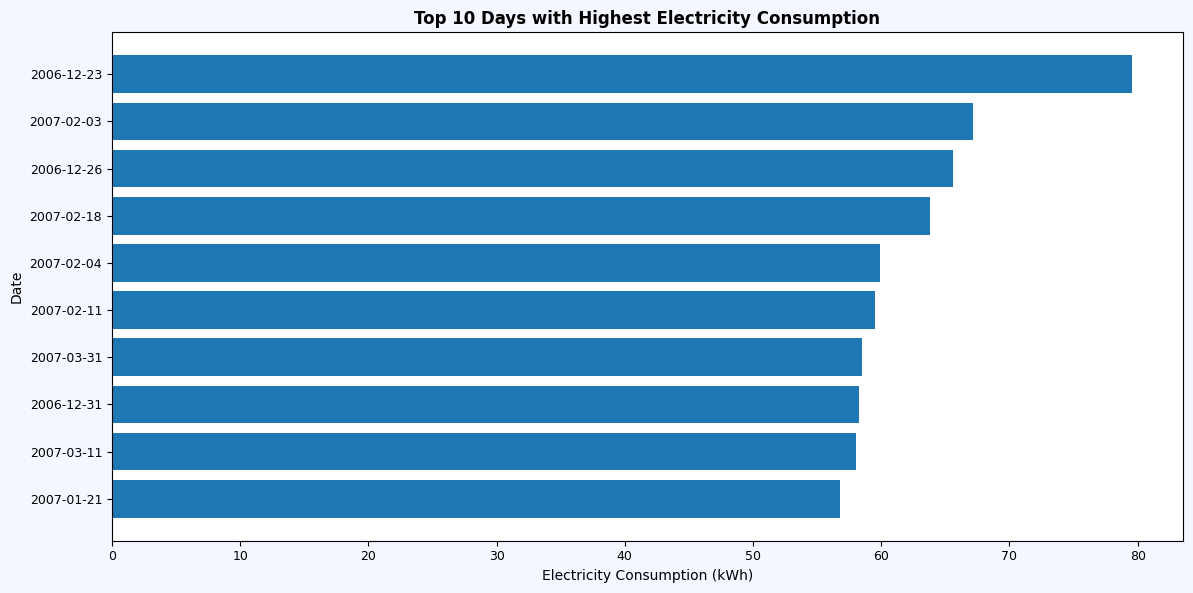

In [ ]:

plt.figure(figsize=(12, 6))

plt.barh(
    top_10_days["Date"].astype(str),
    top_10_days["Daily_Consumption_kWh"]
)

plt.title("Top 10 Days with Highest Electricity Consumption")
plt.xlabel("Electricity Consumption (kWh)")
plt.ylabel("Date")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:

print("DESCRIPTIVE STATISTICS")
print("----------------------")

print(daily_consumption["Daily_Consumption_kWh"].describe().round(2))


DESCRIPTIVE STATISTICS
----------------------
count    1433.00
mean       26.02
std        10.11
min         0.24
25%        19.43
50%        25.71
75%        31.56
max        79.56
Name: Daily_Consumption_kWh, dtype: float64


In [ ]:
df_clean["Week"] = df_clean["Datetime"].dt.to_period("W").astype(str)

weekly_consumption = (
    df_clean.groupby("Week")["Energy_kWh"]
    .sum()
    .reset_index()
)

weekly_consumption.columns = ["Week", "Weekly_Consumption_kWh"]

print("WEEKLY ELECTRICITY CONSUMPTION")
print(weekly_consumption.head(10).round(2))

WEEKLY ELECTRICITY CONSUMPTION
                    Week  Weekly_Consumption_kWh
0  2006-12-11/2006-12-17                   76.66
1  2006-12-18/2006-12-24                  291.29
2  2006-12-25/2006-12-31                  328.94
3  2007-01-01/2007-01-07                  249.35
4  2007-01-08/2007-01-14                  269.61
5  2007-01-15/2007-01-21                  275.43
6  2007-01-22/2007-01-28                  254.91
7  2007-01-29/2007-02-04                  286.21
8  2007-02-05/2007-02-11                  251.15
9  2007-02-12/2007-02-18                  256.42


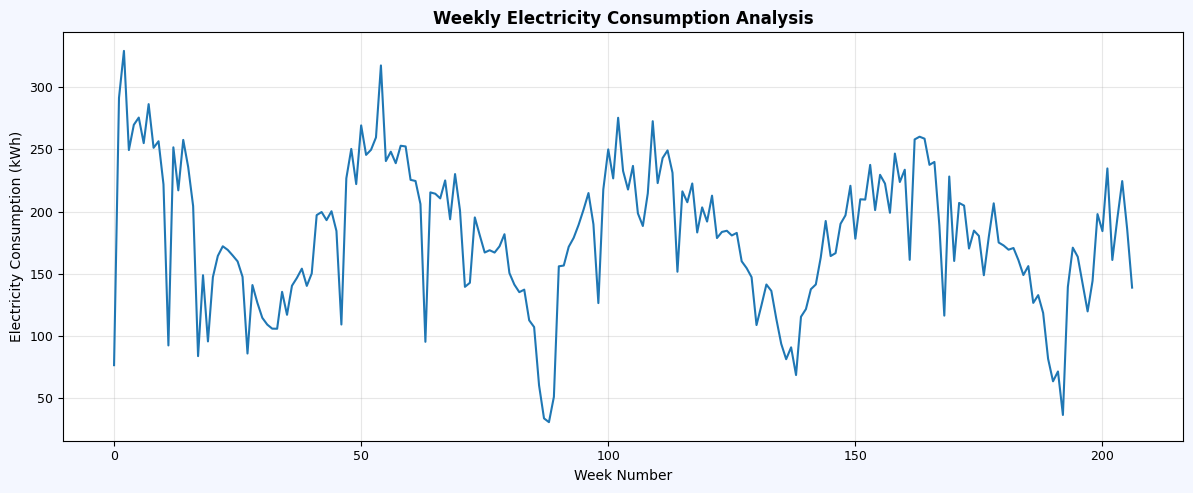

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    range(len(weekly_consumption)),
    weekly_consumption["Weekly_Consumption_kWh"],
    linewidth=1.5
)

plt.title("Weekly Electricity Consumption Analysis")
plt.xlabel("Week Number")
plt.ylabel("Electricity Consumption (kWh)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:

sub_metering = df_clean[
    ["Sub_metering_1", "Sub_metering_2", "Sub_metering_3"]
].mean()

print("AVERAGE SUB-METERING VALUES")
print("---------------------------")
print(sub_metering.round(2))


AVERAGE SUB-METERING VALUES
---------------------------
Sub_metering_1    1.12
Sub_metering_2    1.30
Sub_metering_3    6.46
dtype: float64


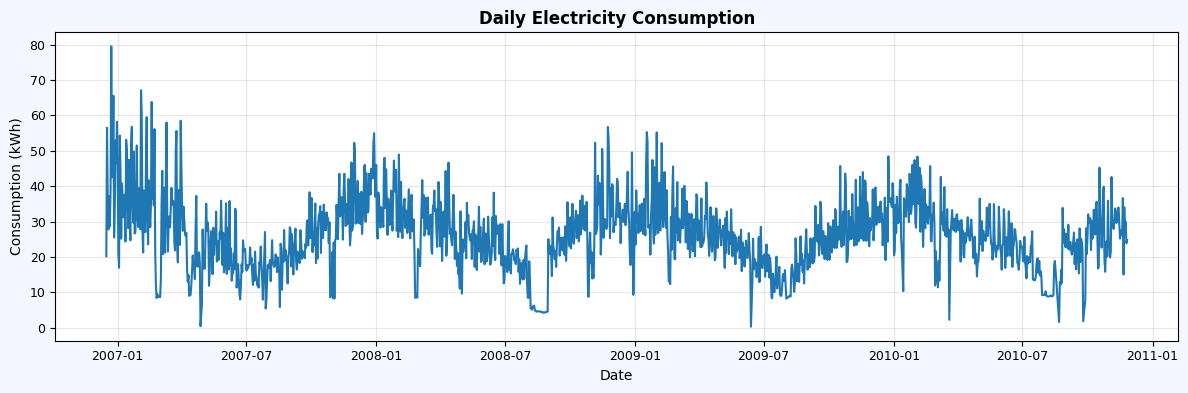

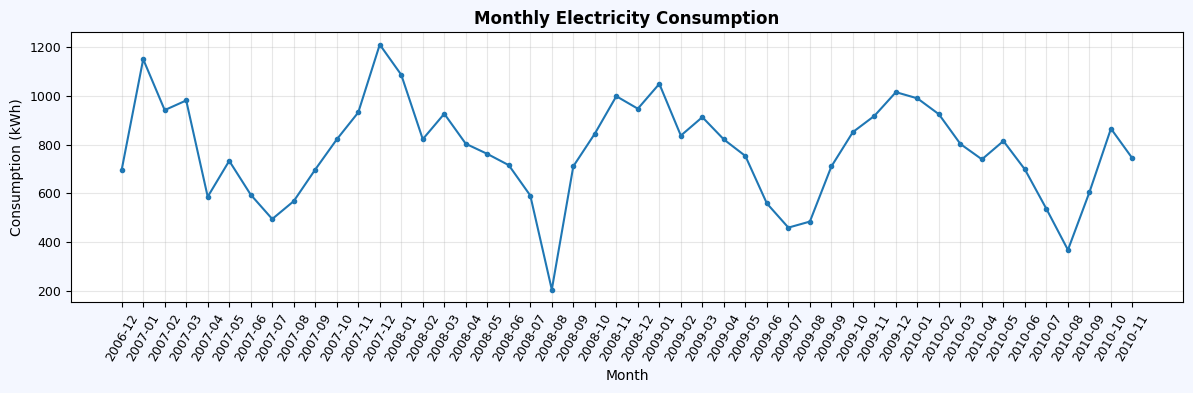

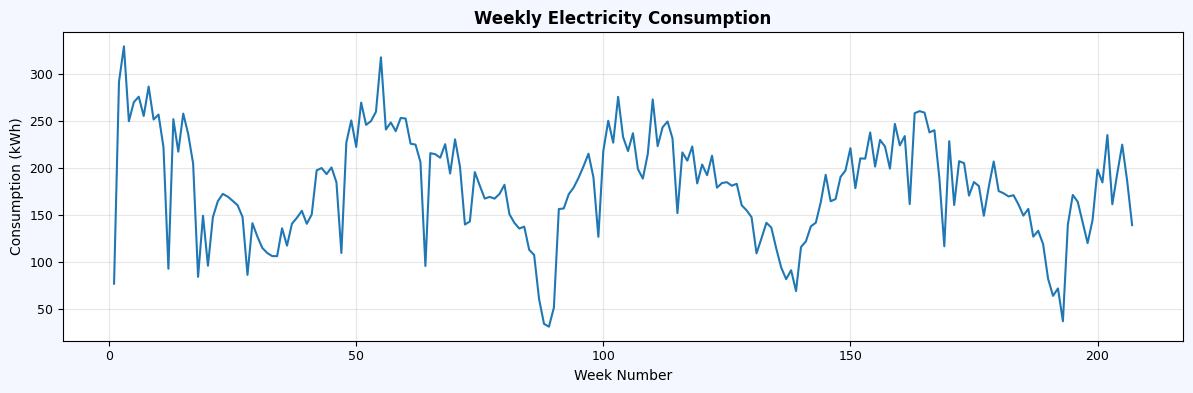

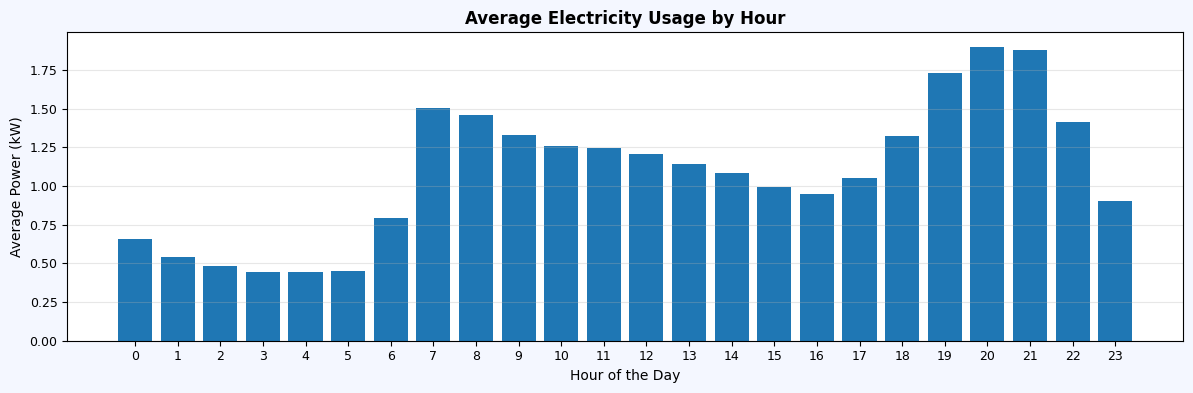

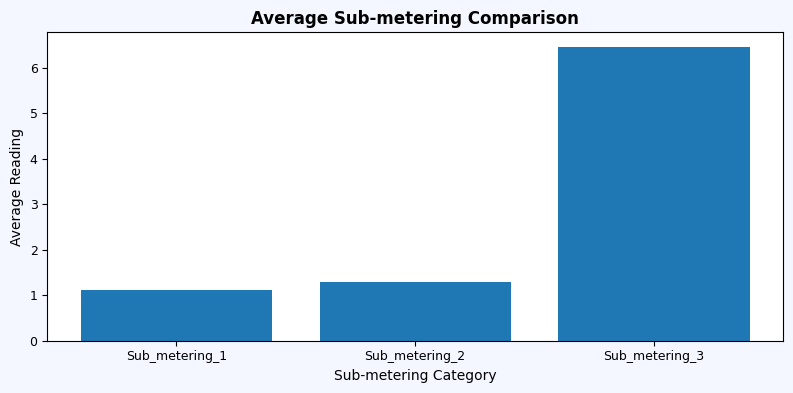

In [ ]:

from IPython.display import display, HTML
import matplotlib.pyplot as plt
import pandas as pd

# Prepare dashboard data
total_days = daily_consumption["Date"].nunique()
average_daily = daily_consumption["Daily_Consumption_kWh"].mean()
highest_daily = daily_consumption["Daily_Consumption_kWh"].max()
lowest_daily = daily_consumption["Daily_Consumption_kWh"].min()
peak_usage_hour = int(peak_hour["Hour"])

# Dashboard heading
display(HTML("""
<h1 style="text-align:center;">⚡ Electricity Consumption Dashboard</h1>
<p style="text-align:center;">
Individual Household Electric Power Consumption Analysis
</p>
<hr>
"""))

# Summary cards
display(HTML(f"""
<div style="display:flex; flex-wrap:wrap; gap:12px; text-align:center;">
<div style="flex:1; min-width:130px; background:#e8f0fe; padding:18px; border-radius:10px;">
<h3>Total Days</h3><h2>{total_days:,}</h2>
</div>
<div style="flex:1; min-width:130px; background:#e6f4ea; padding:18px; border-radius:10px;">
<h3>Average Daily Usage</h3><h2>{average_daily:.2f} kWh</h2>
</div>
<div style="flex:1; min-width:130px; background:#fce8e6; padding:18px; border-radius:10px;">
<h3>Highest Daily Usage</h3><h2>{highest_daily:.2f} kWh</h2>
</div>
<div style="flex:1; min-width:130px; background:#fef7e0; padding:18px; border-radius:10px;">
<h3>Peak Usage Hour</h3><h2>{peak_usage_hour}:00</h2>
</div>
</div>
"""))

# Chart 1: Daily consumption
plt.figure(figsize=(12, 4))
plt.plot(daily_consumption["Date"],
         daily_consumption["Daily_Consumption_kWh"])
plt.title("Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: Monthly consumption
plt.figure(figsize=(12, 4))
plt.plot(monthly_consumption["Month"],
         monthly_consumption["Monthly_Consumption_kWh"],
         marker="o", markersize=3)
plt.title("Monthly Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Consumption (kWh)")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 3: Weekly consumption
plt.figure(figsize=(12, 4))
plt.plot(range(1, len(weekly_consumption) + 1),
         weekly_consumption["Weekly_Consumption_kWh"])
plt.title("Weekly Electricity Consumption")
plt.xlabel("Week Number")
plt.ylabel("Consumption (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 4: Hourly average power
plt.figure(figsize=(12, 4))
plt.bar(hourly_consumption["Hour"],
        hourly_consumption["Average_Power_kW"])
plt.title("Average Electricity Usage by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Power (kW)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 5: Sub-metering comparison
plt.figure(figsize=(8, 4))
plt.bar(sub_metering.index, sub_metering.values)
plt.title("Average Sub-metering Comparison")
plt.xlabel("Sub-metering Category")
plt.ylabel("Average Reading")
plt.tight_layout()
plt.show()

# Key findings
display(HTML(f"""
<h2>Key Findings</h2>
<ul>
<li>Average daily consumption: {average_daily:.2f} kWh</li>
<li>Highest daily consumption: {highest_daily:.2f} kWh</li>
<li>Lowest daily consumption: {lowest_daily:.2f} kWh</li>
<li>Peak average power usage occurs around {peak_usage_hour}:00.</li>
</ul>
<p><i>Note: Results are based on available readings after incomplete records
were removed. Consumption totals may be underestimated where readings are missing.</i></p>
<h3 style="text-align:center;">Dashboard Completed</h3>
"""))


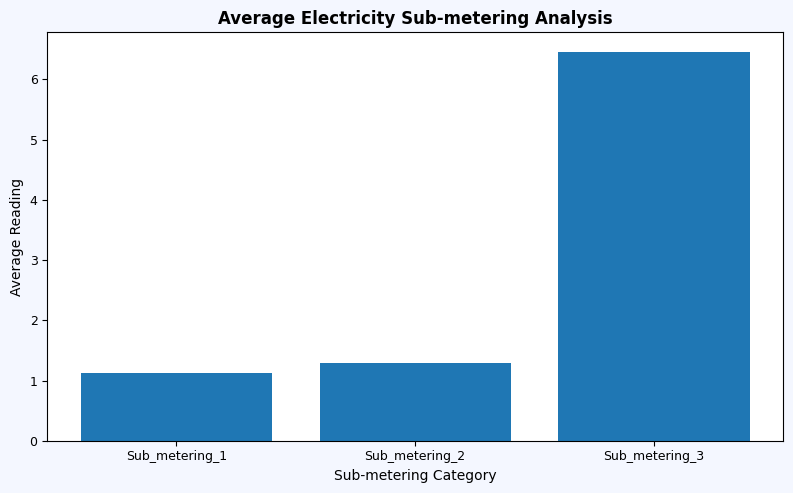

In [ ]:

plt.figure(figsize=(8, 5))

plt.bar(
    sub_metering.index,
    sub_metering.values
)

plt.title("Average Electricity Sub-metering Analysis")
plt.xlabel("Sub-metering Category")
plt.ylabel("Average Reading")
plt.tight_layout()
plt.show()


In [ ]:

print("ELECTRICITY CONSUMPTION ANALYSIS - KEY FINDINGS")
print("=" * 50)

print("1. Average daily consumption:",
      round(daily_consumption["Daily_Consumption_kWh"].mean(), 2), "kWh")

print("2. Highest daily consumption:",
      round(daily_consumption["Daily_Consumption_kWh"].max(), 2), "kWh")

print("3. Highest consumption date:",
      daily_consumption.loc[
          daily_consumption["Daily_Consumption_kWh"].idxmax(), "Date"
      ])

print("4. Peak usage hour:",
      int(peak_hour["Hour"]), "hours")

print("5. Average power at peak hour:",
      round(peak_hour["Average_Power_kW"], 2), "kW")

print("6. Number of complete records:", len(df_clean))


ELECTRICITY CONSUMPTION ANALYSIS - KEY FINDINGS
1. Average daily consumption: 26.02 kWh
2. Highest daily consumption: 79.56 kWh
3. Highest consumption date: 2006-12-23
4. Peak usage hour: 20 hours
5. Average power at peak hour: 1.9 kW
6. Number of complete records: 2049280


In [ ]:

!pip install streamlit


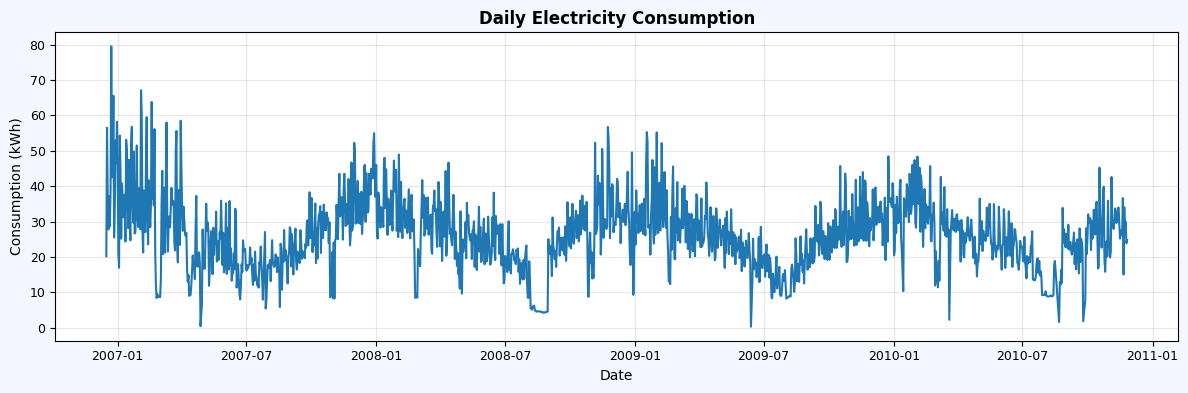

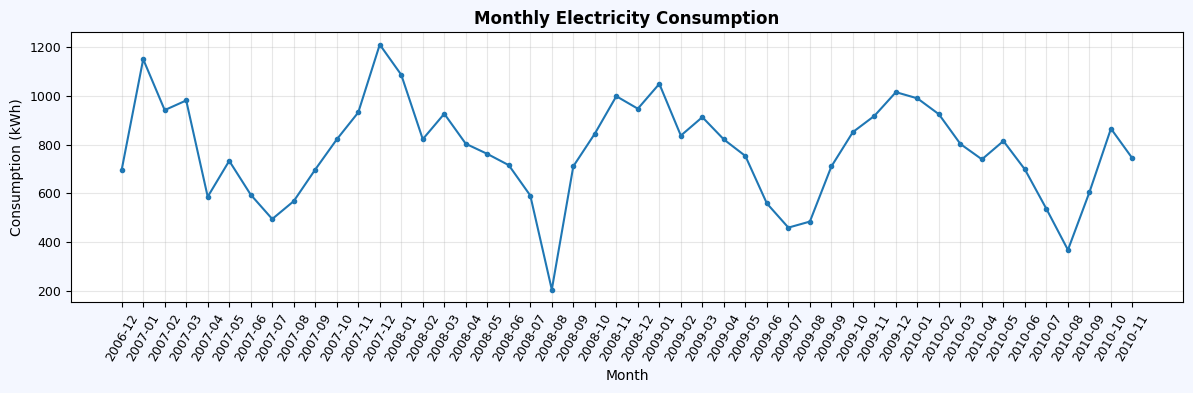

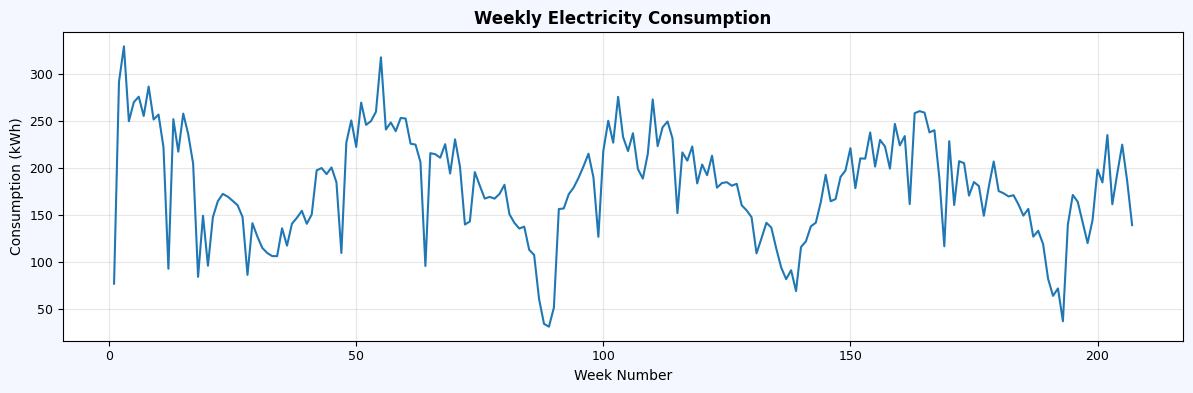

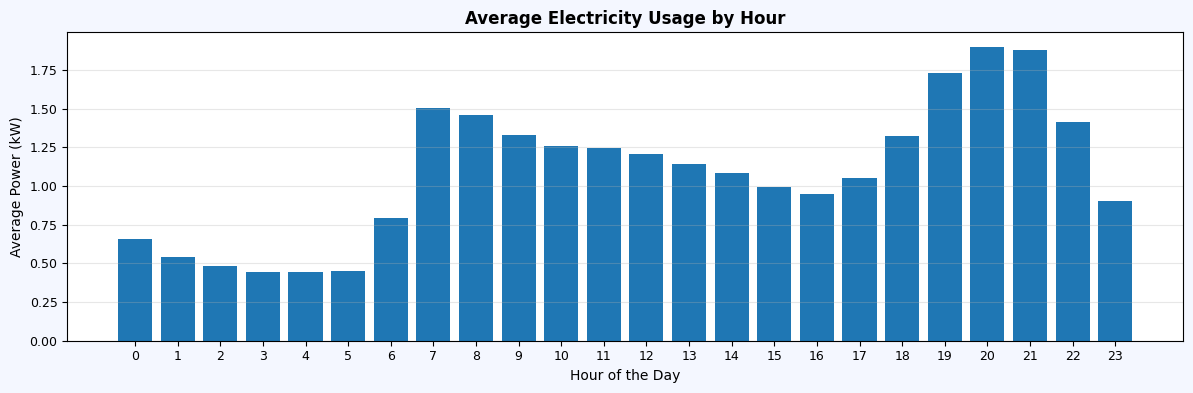

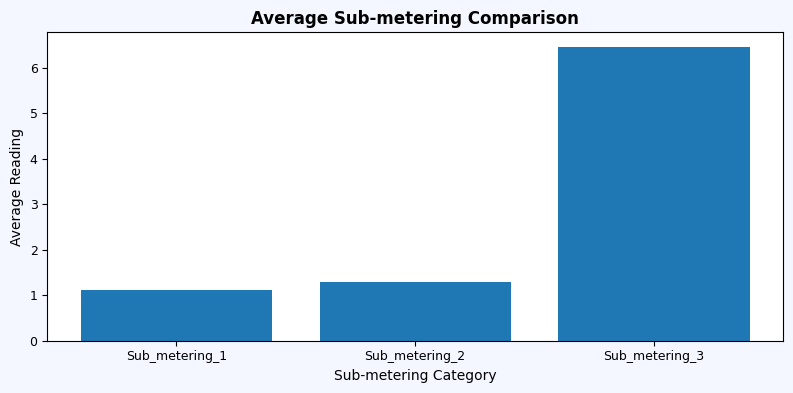

In [ ]:

from IPython.display import display, HTML
import matplotlib.pyplot as plt
import pandas as pd

# Prepare dashboard data
total_days = daily_consumption["Date"].nunique()
average_daily = daily_consumption["Daily_Consumption_kWh"].mean()
highest_daily = daily_consumption["Daily_Consumption_kWh"].max()
lowest_daily = daily_consumption["Daily_Consumption_kWh"].min()
peak_usage_hour = int(peak_hour["Hour"])

# Dashboard heading
display(HTML("""
<h1 style="text-align:center;">⚡ Electricity Consumption Dashboard</h1>
<p style="text-align:center;">
Individual Household Electric Power Consumption Analysis
</p>
<hr>
"""))

# Summary cards
display(HTML(f"""
<div style="display:flex; flex-wrap:wrap; gap:12px; text-align:center;">
<div style="flex:1; min-width:130px; background:#e8f0fe; padding:18px; border-radius:10px;">
<h3>Total Days</h3><h2>{total_days:,}</h2>
</div>
<div style="flex:1; min-width:130px; background:#e6f4ea; padding:18px; border-radius:10px;">
<h3>Average Daily Usage</h3><h2>{average_daily:.2f} kWh</h2>
</div>
<div style="flex:1; min-width:130px; background:#fce8e6; padding:18px; border-radius:10px;">
<h3>Highest Daily Usage</h3><h2>{highest_daily:.2f} kWh</h2>
</div>
<div style="flex:1; min-width:130px; background:#fef7e0; padding:18px; border-radius:10px;">
<h3>Peak Usage Hour</h3><h2>{peak_usage_hour}:00</h2>
</div>
</div>
"""))

# Chart 1: Daily consumption
plt.figure(figsize=(12, 4))
plt.plot(daily_consumption["Date"],
         daily_consumption["Daily_Consumption_kWh"])
plt.title("Daily Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Consumption (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: Monthly consumption
plt.figure(figsize=(12, 4))
plt.plot(monthly_consumption["Month"],
         monthly_consumption["Monthly_Consumption_kWh"],
         marker="o", markersize=3)
plt.title("Monthly Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Consumption (kWh)")
plt.xticks(rotation=60)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 3: Weekly consumption
plt.figure(figsize=(12, 4))
plt.plot(range(1, len(weekly_consumption) + 1),
         weekly_consumption["Weekly_Consumption_kWh"])
plt.title("Weekly Electricity Consumption")
plt.xlabel("Week Number")
plt.ylabel("Consumption (kWh)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 4: Hourly average power
plt.figure(figsize=(12, 4))
plt.bar(hourly_consumption["Hour"],
        hourly_consumption["Average_Power_kW"])
plt.title("Average Electricity Usage by Hour")
plt.xlabel("Hour of the Day")
plt.ylabel("Average Power (kW)")
plt.xticks(range(24))
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 5: Sub-metering comparison
plt.figure(figsize=(8, 4))
plt.bar(sub_metering.index, sub_metering.values)
plt.title("Average Sub-metering Comparison")
plt.xlabel("Sub-metering Category")
plt.ylabel("Average Reading")
plt.tight_layout()
plt.show()

# Key findings
display(HTML(f"""
<h2>Key Findings</h2>
<ul>
<li>Average daily consumption: {average_daily:.2f} kWh</li>
<li>Highest daily consumption: {highest_daily:.2f} kWh</li>
<li>Lowest daily consumption: {lowest_daily:.2f} kWh</li>
<li>Peak average power usage occurs around {peak_usage_hour}:00.</li>
</ul>
<p><i>Note: Results are based on available readings after incomplete records
were removed. Consumption totals may be underestimated where readings are missing.</i></p>
<h3 style="text-align:center;">Dashboard Completed</h3>
"""))
